# The same transmission and mean delay, different information at the deadline

What does a spectrum leave out when an observer has a finite collection window? A lossless dispersive element can redistribute a coherent packet in time without changing its spectral transmission probability. This notebook compares that element with a pure delay matched to its spectrum-weighted mean group delay.

Both elements follow the same Schwarzschild scattering channel. Source preparation, emission phases, observer lapse, detector, efficiency, and the $120M$ deadline stay fixed. The emitted source and transmission grids are supplied inputs from the propagation-controls calculation. Their hashes are checked before use. This notebook regenerates both arms and their detector outputs, rather than regenerating the source or radial scattering solution.

The routed cascade excludes back-propagation into the original scatterer. The comparison therefore describes a specified receiving path after scattering.

## Define the two causal arms

With $x=M\omega$, $x_0=0.16$, and $\gamma_a=0.032$, the all-pass factor and matched delay are

$$A(x)=\frac{x-x_0-i\gamma_a}{x-x_0+i\gamma_a},\qquad D(x)=e^{ixd_*}.$$

For real frequencies $|A|=1$. Its pole lies in the lower half-plane for the inverse $e^{-i\omega t}$ convention. The mean delay $d_*$ averages $2\gamma_a/[(x-x_0)^2+\gamma_a^2]$ against the transmitted packet spectrum. The baseline rule fixes that delay before recovery is evaluated, and the same value is retained during refinement. No peaks are realigned and no waveform is renormalized within the window.

The downstream detector starts empty at zero. The upstream resonator can already contain energy from the packet's prehistory. That storage is inaccessible to the observer and is explicitly included in the energy accounting.

In [1]:
from pathlib import Path
import os,sys,datetime,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0,str(Path('code').resolve()))
from causal_phase import run_experiment
from threadpoolctl import threadpool_limits
OUTPUT=Path('outputs/runs')/os.environ.get('ODER_RUN_NAME',datetime.datetime.now().strftime('%Y%m%d_%H%M%S'))/'causal_phase'
with threadpool_limits(limits=1):run_experiment(OUTPUT)
summary=pd.read_csv(OUTPUT/'summary.csv');display(summary)

baseline schwarzschild completed


baseline matched_delay completed


baseline causal_allpass completed


baseline independent causal check: {"setting": "baseline", "maximum_unit_modulus_error": 8.881784197001252e-16, "maximum_pointwise_transmission_probability_difference": 8.881784197001252e-16, "recomputed_mean_delay_M": 41.90322984921114, "frozen_delay_M": 41.90322984921114, "maximum_upstream_energy_residual": 2.7755575615628914e-15, "maximum_spectral_vs_causal_waveform_error": 3.039026348274152e-11, "maximum_spectral_vs_causal_state_error": 1.1700502181681718e-10, "zero_start_minus800_state_error_bound_at0": 3.1375832924232934e-19, "zero_start_minus400_state_error_bound_at0": 3.493426103966879e-13, "baseline_reproduction_error": 2.220446049250313e-16}


refined schwarzschild completed


refined matched_delay completed


refined causal_allpass completed


refined independent causal check: {"setting": "refined", "maximum_unit_modulus_error": 8.881784197001252e-16, "maximum_pointwise_transmission_probability_difference": 8.881784197001252e-16, "recomputed_mean_delay_M": 41.90323026965188, "frozen_delay_M": 41.90322984921114, "maximum_upstream_energy_residual": 2.6471880243406076e-15, "maximum_spectral_vs_causal_waveform_error": 1.8994475028498215e-12, "maximum_spectral_vs_causal_state_error": 7.313042134985224e-12, "zero_start_minus800_state_error_bound_at0": 2.1913583303239325e-19, "zero_start_minus400_state_error_bound_at0": 3.286483041508346e-13, "baseline_reproduction_error": 2.7755575615628914e-16}


 setting            arm  spectral_transmission  mean_collected  mean_no_early  mean_full_early  fidelity_ceiling  fidelity_floor  maximum_detector_energy_residual  maximum_information_minus_incident_supply
baseline  schwarzschild               0.722212        0.445132       0.018876         0.856854          0.357162        0.815598                      1.866562e-15                                  -0.065888
baseline  matched_delay               0.722212        0.396945       0.013294         0.816954          0.339101        0.771424                      1.319691e-15                                  -0.040872
baseline causal_allpass               0.722212        0.381317       0.011939         0.801126          0.334389        0.754658                      1.074661e-15                                  -0.036291
 refined  schwarzschild               0.722212        0.445132       0.018876         0.856854          0.357162        0.815598                      2.867498e-15              

,setting,arm,spectral_transmission,mean_collected,mean_no_early,mean_full_early,fidelity_ceiling,fidelity_floor,maximum_detector_energy_residual,maximum_information_minus_incident_supply
0,baseline,schwarzschild,0.722212,0.445132,0.018876,0.856854,0.357162,0.815598,1.866562e-15,-0.065888
1,baseline,matched_delay,0.722212,0.396945,0.013294,0.816954,0.339101,0.771424,1.319691e-15,-0.040872
2,baseline,causal_allpass,0.722212,0.381317,0.011939,0.801126,0.334389,0.754658,1.074661e-15,-0.036291
3,refined,schwarzschild,0.722212,0.445132,0.018876,0.856854,0.357162,0.815598,2.867498e-15,-0.065888
4,refined,matched_delay,0.722212,0.396946,0.013294,0.816954,0.339101,0.771425,1.421606e-15,-0.040872
5,refined,causal_allpass,0.722212,0.381318,0.011939,0.801127,0.334390,0.754659,2.374836e-15,-0.036291


## Read recovery state by state

Carrier collection is averaged over the five packets. Information is evaluated for each of the 32 source states before taking an ensemble mean. The aggregate recovery inequalities are also applied separately to each state; their extrema are not obtained by applying an inequality to the adjacent mean-information column.

The matched-delay and all-pass arms have the same spectral transmission. Their finite-window collection and information differ because the detector sees different temporal interference. The magnitude-only diagnostic in the propagation-controls notebook asks a different question and need not define a causal channel.

In [2]:
states=pd.read_csv(OUTPUT/'states.csv');packets=pd.read_csv(OUTPUT/'packets.csv')
refined=summary.query("setting=='refined'").set_index('arm')
delta=refined.loc['causal_allpass','mean_full_early']-refined.loc['matched_delay','mean_full_early']
assert abs(delta+.0158278001)<5.1e-10
display(packets)
a=states.query("setting=='refined' and arm=='causal_allpass'").set_index('seed')
b=states.query("setting=='refined' and arm=='matched_delay'").set_index('seed')
paired=a.full_early-b.full_early
assert np.all(paired<0)
print('Mean full-early information change:',format(delta,'.15g'))
display(pd.DataFrame({'seed':paired.index,'information_change':paired.to_numpy()}))

,setting,arm,packet,incident,collected,detector_memory
0,baseline,schwarzschild,1,0.694831,0.428148,9.927422e-08
1,baseline,schwarzschild,2,0.718247,0.447060,1.746861e-06
2,baseline,schwarzschild,3,0.721869,0.450370,2.688804e-05
3,baseline,schwarzschild,4,0.721960,0.450610,2.999328e-04
4,baseline,schwarzschild,5,0.719684,0.449470,2.180099e-03
5,baseline,matched_delay,1,0.721688,0.450494,5.859456e-04
6,baseline,matched_delay,2,0.717343,0.448190,3.677615e-03
7,baseline,matched_delay,3,0.692640,0.433637,1.408407e-02
8,baseline,matched_delay,4,0.607722,0.381059,3.213039e-02
9,baseline,matched_delay,5,0.433884,0.271345,4.300686e-02


Mean full-early information change: -0.0158278000957542


,seed,information_change
0,2026082100,-0.015778
1,2026082101,-0.015737
2,2026082102,-0.015697
3,2026082103,-0.015895
4,2026082104,-0.015817
5,2026082105,-0.015852
6,2026082106,-0.015872
7,2026082107,-0.015839
8,2026082108,-0.015805
9,2026082109,-0.015769


## Check the resonator state, prehistory, and energy

A separate time-domain calculation integrates the resonator state from $-400M$. Its initial amplitude comes from the full-spectrum packet state at that time. The spectral and time-domain waveforms are then compared on the collection window.

The balance includes incoming energy, outgoing energy, and resonator storage at both ends. The tables also bound the effect at zero of starting the far-past state at zero. Their finite prehistory intervals are reported explicitly. The upstream stored energy is never added to the observer's available register.

Refinement changes the supplied transmission grid, packet quadrature, and temporal resolution while preserving the frozen source phases and delay rule. Raw changes and residuals remain visible.

,setting,maximum_unit_modulus_error,maximum_pointwise_transmission_probability_difference,recomputed_mean_delay_M,frozen_delay_M,maximum_upstream_energy_residual,maximum_spectral_vs_causal_waveform_error,maximum_spectral_vs_causal_state_error,zero_start_minus800_state_error_bound_at0,zero_start_minus400_state_error_bound_at0,baseline_reproduction_error
0,baseline,8.881784e-16,8.881784e-16,41.90323,41.90323,2.775558e-15,3.039026e-11,1.170050e-10,3.137583e-19,3.493426e-13,2.220446e-16
1,refined,8.881784e-16,8.881784e-16,41.90323,41.90323,2.647188e-15,1.899448e-12,7.313042e-12,2.191358e-19,3.286483e-13,2.775558e-16


,setting,packet,incoming_energy_minus400_to0,outgoing_energy_minus400_to0,upstream_storage_at_minus400,upstream_storage_at0,upstream_storage_at_deadline,incoming_energy0_to_deadline,outgoing_energy0_to_deadline
0,baseline,1,2.738108e-02,5.191336e-03,5.905205e-14,2.218974e-02,0.014502,0.694831,0.702519
1,baseline,2,3.963700e-03,1.065919e-03,6.250375e-14,2.897781e-03,0.032393,0.718247,0.688752
2,baseline,3,3.270344e-04,1.118979e-04,2.975539e-14,2.151364e-04,0.070959,0.721869,0.651125
3,baseline,4,1.496413e-05,6.092343e-06,3.254949e-14,8.871782e-06,0.147934,0.721960,0.574035
4,baseline,5,3.684198e-07,1.700820e-07,6.394985e-14,1.983379e-07,0.278513,0.719684,0.441172
5,refined,1,2.738175e-02,5.191431e-03,5.659776e-14,2.219032e-02,0.014501,0.694830,0.702519
6,refined,2,3.963830e-03,1.065949e-03,4.658222e-14,2.897881e-03,0.032393,0.718247,0.688752
7,refined,3,3.270480e-04,1.119023e-04,3.694226e-14,2.151457e-04,0.070958,0.721869,0.651126
8,refined,4,1.496488e-05,6.092659e-06,4.062321e-14,8.872222e-06,0.147932,0.721960,0.574036
9,refined,5,3.684405e-07,1.700958e-07,4.647437e-14,1.983447e-07,0.278510,0.719684,0.441174


,arm,maximum_terminal_collection_change,maximum_information_change,maximum_bound_change
0,schwarzschild,5.176200e-07,1.710150e-07,1.048456e-07
1,matched_delay,1.952150e-06,1.034285e-06,7.135721e-07
2,causal_allpass,1.531533e-06,9.209533e-07,6.580246e-07


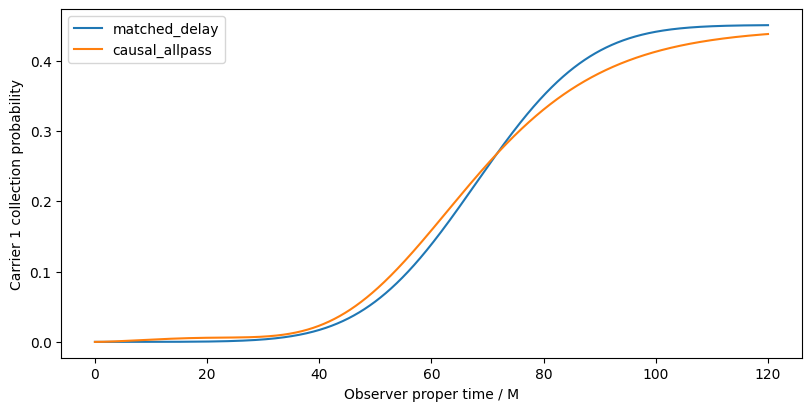

In [3]:
validation=pd.read_csv(OUTPUT/'validation.csv');bookkeeping=pd.read_csv(OUTPUT/'upstream_bookkeeping.csv')
refinement=pd.read_csv(OUTPUT/'refinement.csv')
display(validation);display(bookkeeping);display(refinement)
assert validation.maximum_upstream_energy_residual.max()<2e-8
assert validation.maximum_spectral_vs_causal_waveform_error.max()<2e-8
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
for arm in ['matched_delay','causal_allpass']:
    with np.load(OUTPUT/f'refined_{arm}.npz') as z:ax.plot(z['times'],z['collected'][:,0],label=arm)
ax.set(xlabel='Observer proper time / M',ylabel='Carrier 1 collection probability');ax.legend()
fig.savefig(OUTPUT/'causal_phase_comparison.png',dpi=170,metadata={'Software':None});plt.show()

In all 32 supplied source states, the dispersive arm yields less full-early reference information by the deadline than the matched delay. The refined mean decrease is about 0.01583 in normalized information. Matching spectral transmission and mean delay therefore does not determine finite-window access.

A subsequent receiving channel determines which of those correlations enter retained memory.
